# Assignment 2 — Word Representations (Word Vectors)
**Project:** emotion classification of Reddit comments (GoEmotions) · cleaned corpus from Assignment 1  
**Team:** `<team name>` · **Members:** `<names + roll numbers>`  <!-- TODO: fill in before submitting -->

All representations use the **same cleaned TRAIN split** (36,189 comments) from `data/processed/goemotions_clean.csv`. Using train only keeps dev/test untouched for Phase 3.

In [1]:
import sys, os, math, warnings
sys.path.append('..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from src import representations as R
if not (R.MODEL_DIR / 'fasttext.model').exists():
    from src.run_phase2 import main; main()      # trains + saves models once
train = R.load_clean('train'); docs = train.text_clean.tolist()
print(len(docs), 'documents;', sum(len(d.split()) for d in docs), 'tokens')
train[['text_raw','text_clean','label']].head(3)

36189 documents; 245516 tokens


,text_raw,text_clean,label
0,My favourite food is anything I didn't have to...,favourite food anything not cook,neutral
1,"Now if he does off himself, everyone will thin...",everyone think he laugh screwing people instea...,neutral
2,WHY THE FUCK IS BAYLESS ISOING,fuck bayless isoing,anger


## Part A — Count-based representations

### A1. Bag of Words

In [2]:
bow_vec, X_bow = R.build_bow(docs, (1,1), min_df=1)
print('BoW shape (documents x vocabulary):', X_bow.shape)
print('non-zero entries:', X_bow.nnz, '| average non-zeros per document:', round(X_bow.nnz / X_bow.shape[0], 2))
print(f'sparsity: {R.sparsity(X_bow):.4f}% of entries are zero')
_, X_bow2 = R.build_bow(docs, (1,1), min_df=2)
print('with min_df=2 (words in >=2 comments):', X_bow2.shape, f'sparsity {R.sparsity(X_bow2):.4f}%')

BoW shape (documents x vocabulary): (36189, 19534)
non-zero entries: 238136 | average non-zeros per document: 6.58
sparsity: 99.9663% of entries are zero


with min_df=2 (words in >=2 comments): (36189, 9413) sparsity 99.9331%


A comment has only ~6.6 distinct words but the vocabulary has ~19.5k, so >99.9% of the matrix is zeros — it must be stored sparsely. Words seen once (about half of the vocabulary) add columns that can never generalise, which is why we use `min_df=2` for the saved vectorizers.

### A2. TF-IDF

In [3]:
tf_vec, X_tfidf = R.build_tfidf(docs, (1,1), min_df=2)
names = tf_vec.get_feature_names_out(); idf = dict(zip(names, tf_vec.idf_))
by_idf = sorted(idf.items(), key=lambda kv: kv[1])
print('COMMON words, lowest IDF (pushed toward zero weight):')
for w, v in by_idf[:8]: print(f'   {w:10s} idf={v:.2f}  (appears in {int(round((len(docs)+1)/math.exp(v-1)-1))} of {len(docs)} comments)')
print('RARE words, highest IDF:', [(w, round(v,2)) for w, v in by_idf[-4:]])

# concrete example: a long comment
i = max(range(200), key=lambda k: len(docs[k].split()))
row = X_tfidf[i].toarray()[0]
weights = sorted([(names[j], round(row[j],3)) for j in row.nonzero()[0]], key=lambda x: -x[1])
print('\ncomment:', docs[i]); print('highest TF-IDF:', weights[:4]); print('lowest  TF-IDF:', weights[-4:])

COMMON words, lowest IDF (pushed toward zero weight):
   not        idf=2.57  (appears in 7510 of 36189 comments)
   but        idf=3.51  (appears in 2933 of 36189 comments)
   get        idf=3.54  (appears in 2858 of 36189 comments)
   like       idf=3.59  (appears in 2718 of 36189 comments)
   so         idf=3.61  (appears in 2649 of 36189 comments)
   would      idf=3.84  (appears in 2122 of 36189 comments)
   think      idf=4.04  (appears in 1727 of 36189 comments)
   go         idf=4.08  (appears in 1666 of 36189 comments)
RARE words, highest IDF: [('ziip', np.float64(10.4)), ('zim', np.float64(10.4)), ('zinger', np.float64(10.4)), ('zipper', np.float64(10.4))]

comment: true though either get no shirt freeze death wear stupid look butcher cape hope get something well next season
highest TF-IDF: [('butcher', np.float64(0.347)), ('cape', np.float64(0.341)), ('freeze', np.float64(0.309)), ('shirt', np.float64(0.278))]
lowest  TF-IDF: [('hope', np.float64(0.183)), ('well', np.float64

**Why.** TF-IDF = term frequency × inverse document frequency. A word that appears in almost every comment (`not`, `but`, `get`, `like`) gets a small IDF, so its weight is pushed down even if it is frequent inside one comment. A word that occurs in only a few comments (`butcher`, `cape`, `freeze` in the example) has a large IDF and dominates the vector — these are the words that best *distinguish* this comment from the others. (Note `not` still has a non-zero weight because scikit-learn's smoothed IDF never reaches 0, and we deliberately kept negations.)

### A3. N-grams

,min_df,n-gram range,features,non-zeros,sparsity %
0,1,unigrams,19534,238136,99.9663
1,1,uni+bigrams,168234,446363,99.9927
2,1,uni+bi+trigrams,337102,620432,99.9949
3,2,unigrams,9413,228015,99.9331
4,2,uni+bigrams,28377,306506,99.9702
5,2,uni+bi+trigrams,31271,314601,99.9722


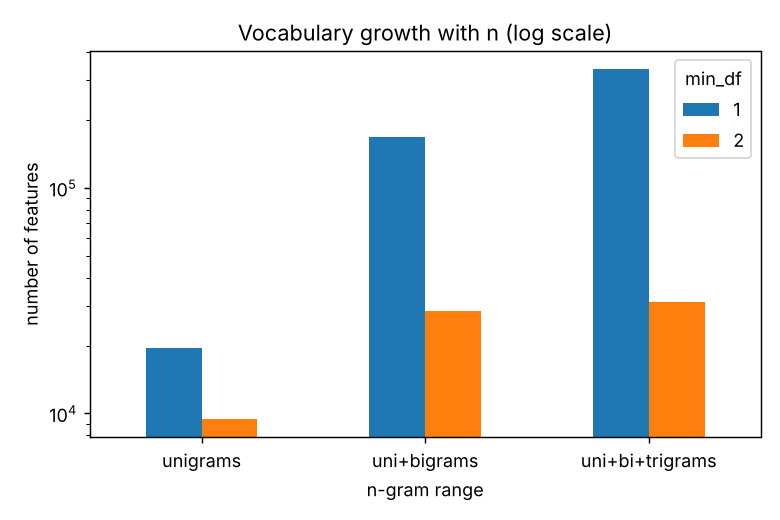

In [4]:
growth = R.ngram_growth_table(docs, min_dfs=(1, 2)); display(growth)
piv = growth.pivot(index='n-gram range', columns='min_df', values='features').loc[['unigrams','uni+bigrams','uni+bi+trigrams']]
ax = piv.plot.bar(figsize=(6,4), rot=0); ax.set_ylabel('number of features'); ax.set_title('Vocabulary growth with n (log scale)'); ax.set_yscale('log')
plt.tight_layout(); plt.savefig('../figures/ngram_growth.png', dpi=130); plt.close(); display(Image('../figures/ngram_growth.png'))

**Trade-off.** Adding bigrams multiplies the feature count by ~8.6× (19.5k → 168k at `min_df=1`) and trigrams reach 337k, while each comment gains only a few non-zeros — sparsity rises from 99.966% to 99.995%. Most n-grams occur once, so they are noise for a 36k-comment corpus; with `min_df=2` the growth is far smaller (9.4k → 28k → 31k). Bigrams capture local context such as negation (`not good`) that unigrams lose, at the price of a much sparser, higher-dimensional matrix.

### A4. Hand-worked numerical example (toy sample)
scikit-learn's TF-IDF (defaults): `tf` = raw count of the word in the document; `idf = ln((1+n)/(1+df)) + 1`; each document vector is then L2-normalised. Below we do the arithmetic ourselves on 4 short documents and compare to the library. **Also redo this on paper and attach the scanned page.**

In [5]:
short = [d for d in docs if 4 <= len(d.split()) <= 5]
# choose 4 short documents that share at least one word (so IDF is interesting)
for seed in range(2000):
    toy = list(pd.Series(short).sample(4, random_state=seed))
    shared = [w for w, c in Counter(w for d in toy for w in set(d.split())).items() if c == 2]
    if shared and len(set(toy)) == 4 and len(toy[0].split()) == 4: break
for k, d in enumerate(toy): print(f'doc{k}:', d)
n = len(toy); target = shared[0]
doc0 = next(d for d in toy if target in d.split()); d0 = toy.index(doc0)
print(f"\nwe compute the TF-IDF weight of '{target}' in doc{d0}")
df_t = sum(target in d.split() for d in toy); tf_t = doc0.split().count(target)
idf_t = math.log((1+n)/(1+df_t)) + 1
print(f'  n = {n} documents, df({target}) = {df_t}, tf = {tf_t}')
print(f'  idf = ln((1+{n})/(1+{df_t})) + 1 = ln({(1+n)/(1+df_t):.4f}) + 1 = {idf_t:.6f}')
raw = {}
for w in doc0.split():
    dfw = sum(w in d.split() for d in toy); raw[w] = doc0.split().count(w) * (math.log((1+n)/(1+dfw)) + 1)
    print(f'  raw weight {w:10s} = tf {doc0.split().count(w)} x idf {math.log((1+n)/(1+dfw))+1:.6f} = {raw[w]:.6f}')
norm = math.sqrt(sum(v*v for v in raw.values()))
print(f'  L2 norm = sqrt({" + ".join(f"{v:.4f}^2" for v in raw.values())}) = {norm:.6f}')
by_hand = raw[target] / norm
print(f"  TF-IDF('{target}', doc{d0}) = {raw[target]:.6f} / {norm:.6f} = {by_hand:.6f}")
lib = TfidfVectorizer().fit(toy); M = lib.transform(toy)
lib_val = M[d0, list(lib.get_feature_names_out()).index(target)]
print(f'  library value               = {lib_val:.6f}   match: {abs(lib_val-by_hand) < 1e-9}')

# bigram by hand
toks = doc0.split(); bigrams = [' '.join(toks[j:j+2]) for j in range(len(toks)-1)]
print('\nbigrams of doc%d by sliding a window of 2:' % d0, bigrams)
bg = bigrams[0]; by_hand_count = bigrams.count(bg)
cv = CountVectorizer(ngram_range=(2,2)).fit(toy); B = cv.transform(toy)
lib_count = B[d0, list(cv.get_feature_names_out()).index(bg)]
print(f"count of bigram '{bg}' in doc{d0}: by hand = {by_hand_count}, library = {lib_count}, match: {by_hand_count == lib_count}")

doc0: never understand streaming entertain
doc1: defeat dragon clean room
doc2: subreddit subscriber but online
doc3: might something but question

we compute the TF-IDF weight of 'but' in doc2
  n = 4 documents, df(but) = 2, tf = 1
  idf = ln((1+4)/(1+2)) + 1 = ln(1.6667) + 1 = 1.510826
  raw weight subreddit  = tf 1 x idf 1.916291 = 1.916291
  raw weight subscriber = tf 1 x idf 1.916291 = 1.916291
  raw weight but        = tf 1 x idf 1.510826 = 1.510826
  raw weight online     = tf 1 x idf 1.916291 = 1.916291
  L2 norm = sqrt(1.9163^2 + 1.9163^2 + 1.5108^2 + 1.9163^2) = 3.646794
  TF-IDF('but', doc2) = 1.510826 / 3.646794 = 0.414289
  library value               = 0.414289   match: True

bigrams of doc2 by sliding a window of 2: ['subreddit subscriber', 'subscriber but', 'but online']
count of bigram 'subreddit subscriber' in doc2: by hand = 1, library = 1, match: True


## Part B — Learned embeddings

In [6]:
print('shared hyper-parameters:', R.W2V_PARAMS)
from src.vectorize import _load
cbow, skip, ft = _load('cbow'), _load('skipgram'), _load('fasttext')
print('vocabulary (min_count=2):', len(cbow.wv), len(skip.wv), len(ft.wv))
print('B1 CBOW      -> sg =', cbow.sg, '| B2 Skip-gram -> sg =', skip.sg, '| fastText sg =', ft.sg, '(min_n=3, max_n=6)')

shared hyper-parameters: {'vector_size': 100, 'window': 5, 'min_count': 2, 'epochs': 30, 'negative': 5, 'workers': 1, 'seed': 42}


vocabulary (min_count=2): 9493 9493 9493
B1 CBOW      -> sg = 0 | B2 Skip-gram -> sg = 1 | fastText sg = 1 (min_n=3, max_n=6)


### B1/B2 — hyper-parameters
`vector_size=100`, `window=5`, `min_count=2`, `epochs=30`, `negative=5`, `seed=42`, `workers=1` (single worker so runs are reproducible). Word2Vec CBOW uses `sg=0`; Skip-gram uses `sg=1`; the only difference between the two models is the training scheme. We use 30 epochs (default is 5) because the corpus is small (~245k tokens).

### B3 — CBOW vs Skip-gram
**CBOW** (context → centre): the vectors of the surrounding words are averaged and used to predict the centre word, so each training window gives one prediction; averaging smooths the context, which makes it fast and good for frequent words. **Skip-gram** (centre → context): the centre word is used to predict each context word separately, giving several predictions per window, so rare words receive many more updates — better for rare words and small data in theory, but slower. *Expectation:* because our corpus is small with many rare words, we expected Skip-gram to do at least as well. *Observed (see Part C):* CBOW actually gave the more sensible neighbours here; Skip-gram's neighbours for common emotion words were noisy. With only ~245k tokens and short (≈7 token) comments, windows contain little context, so none of the models is very reliable — we interpret results cautiously.

### B4 — fastText and sub-word information
Word2Vec learns one vector per whole word, so a word it never saw has no vector. fastText represents a word as the sum of its **character n-grams** (3–6 chars, e.g. `<ha`, `hap`, `app`, `ppy` …), so a misspelling shares most n-grams with the correct word and gets a nearby vector. We train fastText with `sg=1` and the same hyper-parameters as Skip-gram so the only difference is sub-word information.

In [7]:
def top(model, w, n=3):
    try: return [(x, round(s,2)) for x, s in model.wv.most_similar(w, topn=n)]
    except KeyError: return 'KeyError - word not in vocabulary'
rows = []
for w in ['hapy', 'amazingg', 'lovee', 'sooo']:                     # misspelled / out-of-vocabulary
    rows.append({'word': w, 'kind': 'OOV', 'in Word2Vec vocab?': w in skip.wv.key_to_index, 'Word2Vec (skip-gram)': top(skip, w), 'fastText': top(ft, w)})
cnt = Counter(t for d in docs for t in d.split())
for w in ['abt', 'lucrative', 'screwing']:                          # rare words (freq 2)
    rows.append({'word': w, 'kind': f'rare (freq {cnt[w]})', 'in Word2Vec vocab?': w in skip.wv.key_to_index, 'Word2Vec (skip-gram)': top(skip, w), 'fastText': top(ft, w)})
pd.set_option('display.max_colwidth', 80); display(pd.DataFrame(rows))

,word,kind,in Word2Vec vocab?,Word2Vec (skip-gram),fastText
0,hapy,OOV,False,KeyError - word not in vocabulary,"[(happy, 0.86), (happyfriendlybot, 0.76), (happiest, 0.73)]"
1,amazingg,OOV,False,KeyError - word not in vocabulary,"[(amazing, 0.97), (amazingly, 0.87), (ama, 0.73)]"
2,lovee,OOV,False,KeyError - word not in vocabulary,"[(loved, 0.81), (love, 0.76), (lover, 0.69)]"
3,sooo,OOV,False,KeyError - word not in vocabulary,"[(soo, 0.92), (ooo, 0.77), (sofa, 0.73)]"
4,abt,rare (freq 2),True,"[(comin, 0.77), (backyard, 0.75), (frick, 0.74)]","[(dbt, 0.7), (rebuttal, 0.67), (ab, 0.66)]"
5,lucrative,rare (freq 2),True,"[(meow, 0.83), (un-ironically, 0.82), (nb, 0.8)]","[(narrative, 0.88), (native, 0.86), (innovative, 0.86)]"
6,screwing,rare (freq 2),True,"[(nasal, 0.82), (mythology, 0.72), (coordinated, 0.71)]","[(viewing, 0.79), (screening, 0.78), (swing, 0.77)]"


Word2Vec simply raises a `KeyError` for the misspelled words, while fastText returns the intended word (`hapy` → `happy` 0.86, `amazingg` → `amazing` 0.97). For rare words (frequency 2) fastText's neighbours are often dominated by *spelling* similarity rather than meaning, which is also a weakness: it trades semantics for orthography when data is scarce.

## Part C — Probing & comparison

### C1. Nearest neighbours

In [8]:
queries = ['love', 'angry', 'sad', 'thank', 'funny', 'scared']
rows = []
for q in queries:
    rows.append({'word': q, **{name: ', '.join(w for w, _ in m.wv.most_similar(q, topn=5)) for name, m in [('CBOW', cbow), ('Skip-gram', skip), ('fastText', ft)]}})
pd.set_option('display.max_colwidth', 70); display(pd.DataFrame(rows).set_index('word'))

,CBOW,Skip-gram,fastText
word,,,
love,"hate, awesome, amazing, hat, amaze","yaas, crafty, burning, passionately, meow","glove, loved, stove, loove, piggy"
angry,"uncomfortable, sick, toxic, sad, disgust","irrationally, harvard, lecture, mermaid, youve","hangry, hungry, angrily, moronic, harvard"
sad,"uncomfortable, planning, angry, scary, upsetting","relieve, soulmates, septic, depressed, updoot","sacred, icky, mcdonalds, garlic, mnf"
thank,"appreciate, thanks, prayer, invalid, saame","thanks, appreciate, sage, concise, clarification","thankyou, thanks, thang, thankful, thankfully"
funny,"awkward, ugly, strange, disgust, exact","psst, joke, tyl, bmi, hassle","ifunny, unfunny, funnier, funhaus, sunny"
scared,"yaas, lmaoo, cutest, eager, asg","yaas, mania, cockatoo, kool-aid, soulmate","scare, scarf, scarlet, scary, scar"


**Comment.** CBOW gives the most plausible neighbours: `love` → `hate`, `awesome`, `amazing`; `angry` → `sick`, `toxic`, `sad`, `disgust`; `thank` → `appreciate`, `thanks`. (Antonyms like love/hate appear together because they occur in the same contexts — embeddings capture *distribution*, not polarity.) Skip-gram is noisy for most queries (`angry` → `harvard`, `mermaid`), which shows undertraining on a small corpus. fastText neighbours are mostly spelling-related (`love` → `glove`, `stove`; `scared` → `scarf`, `scarlet`), although `thank` → `thanks`, `thankful` works well.

### C2. Similar vs unrelated pairs (cosine similarity)

In [9]:
pairs = [('thank','thanks','similar'), ('angry','mad','similar'), ('happy','glad','similar'), ('good','bad','antonyms'),
         ('love','table','unrelated'), ('sad','banana','unrelated')]
pd.DataFrame([{'pair': f'{a}-{b}', 'expected': e, **{n: round(R.cosine(m, a, b), 3) for n, m in [('CBOW', cbow), ('Skip-gram', skip), ('fastText', ft)]}} for a, b, e in pairs]).set_index('pair')

,expected,CBOW,Skip-gram,fastText
pair,,,,
thank-thanks,similar,0.658,0.687,0.813
angry-mad,similar,0.485,0.366,0.277
happy-glad,similar,0.406,0.326,0.330
good-bad,antonyms,0.451,0.444,0.391
love-table,unrelated,0.234,0.369,0.262
sad-banana,unrelated,0.171,0.347,0.374


**Discussion.** CBOW separates related from unrelated pairs reasonably (e.g. `thank`–`thanks` 0.66, `angry`–`mad` 0.49 vs 0.17–0.23 for the unrelated pairs). Skip-gram and fastText barely separate them: unrelated pairs (`love`–`table`, `sad`–`banana`) score 0.26–0.37, overlapping with several related pairs (`angry`–`mad` 0.28–0.37 in the same two models), so cosine values from these two models should not be trusted on this corpus. Note that `good`–`bad` is high in all models: antonyms are used in the same contexts.

### C3. Analogy

In [10]:
for name, m in [('CBOW', cbow), ('Skip-gram', skip), ('fastText', ft)]:
    print(f'{name:10s} bad + love - good =', [(w, round(s, 2)) for w, s in m.wv.most_similar(positive=['bad', 'love'], negative=['good'], topn=5)])

CBOW       bad + love - good = [('hate', 0.46), ('glimpse', 0.43), ('black', 0.42), ('hat', 0.41), ('paint', 0.41)]
Skip-gram  bad + love - good = [('passionately', 0.41), ('sox', 0.39), ('ale', 0.38), ('pink', 0.38), ('glimpse', 0.37)]
fastText   bad + love - good = [('ba', 0.48), ('badmouth', 0.44), ('glove', 0.44), ('bass', 0.42), ('loved', 0.42)]


Target: `love − good + bad ≈ hate`. CBOW returns `hate` as its top answer (0.46), but this looks like partly luck: its next answers (`glimpse`, `black`, `hat`) are meaningless, and Skip-gram and fastText fail completely (`passionately`, `ba`). With such a small corpus analogies are not reliable; we report this as one success and two failures, not as evidence that the models encode sentiment algebra.

### C4. Count-based vs learned representations on our data

In [11]:
rep = pd.DataFrame([
  {'representation': 'BoW / TF-IDF (unigram, min_df=2)', 'dimensions': X_tfidf.shape[1], 'sparsity %': round(R.sparsity(X_tfidf), 2), 'handles OOV word?': 'No (ignored)', 'captures': 'which words occur (TF-IDF: which are distinctive)'},
  {'representation': 'TF-IDF uni+bigrams (min_df=2)', 'dimensions': 28377, 'sparsity %': 99.97, 'handles OOV word?': 'No', 'captures': 'local word order (e.g. "not good")'},
  {'representation': 'Word2Vec CBOW / Skip-gram', 'dimensions': 100, 'sparsity %': 0.0, 'handles OOV word?': 'No (KeyError)', 'captures': 'distributional similarity of words'},
  {'representation': 'fastText', 'dimensions': 100, 'sparsity %': 0.0, 'handles OOV word?': 'Yes (char n-grams)', 'captures': 'distribution + spelling/morphology'}])
display(rep.set_index('representation'))

,dimensions,sparsity %,handles OOV word?,captures
representation,,,,
"BoW / TF-IDF (unigram, min_df=2)",9413,99.93,No (ignored),which words occur (TF-IDF: which are distinctive)
TF-IDF uni+bigrams (min_df=2),28377,99.97,No,"local word order (e.g. ""not good"")"
Word2Vec CBOW / Skip-gram,100,0.00,No (KeyError),distributional similarity of words
fastText,100,0.00,Yes (char n-grams),distribution + spelling/morphology


Count-based vectors are very high-dimensional (9k–28k) and >99.9% zeros but are fully interpretable (each column is a word or phrase) and need no training. Learned embeddings are small (100 dims) and dense, and place related words close together (`thank`/`appreciate`), something BoW cannot do because every word is an independent axis. Their weakness here is data size: with ~245k tokens the vectors are noisy. Only fastText handles unseen/misspelled words. A *document* vector from embeddings is an average of word vectors, which loses word order, whereas n-gram TF-IDF keeps some of it.

## Part D — Package for the next phase

In [12]:
print(sorted(os.listdir('../models')))
from src.vectorize import vectorize
raw_doc = "I'm sooo happy today!!! thank you 😘"
for m in ['tfidf', 'tfidf_ngram', 'cbow', 'skipgram', 'fasttext']:
    v = vectorize(raw_doc, method=m)
    print(f'{m:12s} -> type {type(v).__name__:12s} shape {v.shape}')
print('\nmisspelled input, fastText:', vectorize('hapy amazingg day', 'fasttext')[:5].round(3), '...')
print('empty / unusable input    :', vectorize('!!!', 'cbow')[:5])

['fasttext.model', 'tfidf_ngram12.joblib', 'tfidf_unigram.joblib', 'w2v_cbow.model', 'w2v_skipgram.model']


tfidf        -> type csr_matrix   shape (1, 9413)
tfidf_ngram  -> type csr_matrix   shape (1, 28377)
cbow         -> type ndarray      shape (100,)
skipgram     -> type ndarray      shape (100,)
fasttext     -> type ndarray      shape (100,)

misspelled input, fastText: [ 0.276  0.178 -0.229  0.08   0.004] ...
empty / unusable input    : [0. 0. 0. 0. 0.]


`vectorize(raw_document, method)` cleans the raw text with the **Assignment-1 pipeline** and returns a sparse TF-IDF row or a 100-d averaged embedding. Models are loaded once from `models/` and cached — nothing is retrained at load time. Methods: `tfidf`, `tfidf_ngram`, `cbow`, `skipgram`, `fasttext`.